# 04 — Filtro de Kalman 2: media y escala del ECT → z-score prior

**Dueño:** Gonzalo Cano (GC) · **Revisor:** Juan Manuel Espinosa (JME) · **Guía:** `docs/instrucciones/04_kalman_senal.md`

**Objetivo.** Estimar en tiempo real la media latente μ̂_t y la escala σ̂_t del ECT dinámico que produce el filtro 1, y
calcular el z-score **con estadísticos prior** (información hasta t − 1). Grupo: tercia GLD-GDX-B (iteración 2):

$$z_t = \frac{ECT_t - \hat\mu_{t|t-1}}{\hat\sigma_{t|t-1}}$$

> Este notebook solo **muestra**: toda la lógica vive en `kalman/signal_filter.py` y es la misma que ejecuta
> `python main.py`. Todo lo que se calibra usa solo entrenamiento.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from cointegration.half_life import compute_half_life
from kalman.signal_filter import (BURN_IN, INNOVATION_VAR_TOLERANCE, SignalFilter, compare_models,
                                  innovation_diagnostics)
from main import ARTIFACTS, FIGURES

pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)

kf1 = pd.read_parquet(ARTIFACTS / "kf1_weights.parquet")
kf2 = pd.read_parquet(ARTIFACTS / "kf2_signal.parquet")
params = json.loads((ARTIFACTS / "params.json").read_text())["kf2"]
active = kf1.loc[~kf1["burn_in"]]
train_ect = active.loc[active["split"] == "train", "ect_dynamic"]
print(f"Filtro 2: {kf2.index[0].date()} → {kf2.index[-1].date()} ({len(kf2)} días; burn-in propio de {BURN_IN})")

Filtro 2: 2013-01-04 → 2026-10-30 (3477 días; burn-in propio de 63)


## 1. La entrada: el ECT dinámico del filtro 1

El profesor aclaró que los "residuales del VECM" que normaliza el filtro 2 son el **término de corrección de error que
el filtro 1 produce día a día** (`ect_dynamic`, calculado con los pesos prior). El filtro 2 arranca el primer día después
del burn-in del filtro 1. Lo importante de esta serie para el modelo: **revierte en semanas, no en un día**.

In [2]:
print(f"ECT dinámico en train (sin burn-in del filtro 1): {len(train_ect)} días")
print(f"  media {train_ect.mean():+.4f}, desviación {train_ect.std():.4f}")
print(f"  autocorrelación de rezago 1: {train_ect.autocorr(1):.3f}  → muy persistente")
print(f"  vida media (OU, sesión 12): {compute_half_life(train_ect):.1f} días")
print(f"  autocorrelación de sus cambios diarios (rezagos 1–3): "
      f"{[round(float(train_ect.diff().autocorr(k)), 3) for k in (1, 2, 3)]}")

ECT dinámico en train (sin burn-in del filtro 1): 1985 días
  media -0.0099, desviación 0.0508
  autocorrelación de rezago 1: 0.969  → muy persistente
  vida media (OU, sesión 12): 22.1 días
  autocorrelación de sus cambios diarios (rezagos 1–3): [-0.158, -0.128, 0.08]


## 2. Por qué estado aumentado y no el nivel local puro de clase

El modelo de clase para la media del spread es el **nivel local**: μ_t = μ_{t−1} + w_t, ECT_t = μ_t + v_t. Supone que
toda desviación de la media es **ruido de un día** (v_t). Nuestro ECT tarda ≈ 22 días en cerrar la mitad de una
desviación, y esa persistencia no cabe en el modelo, así que el filtro tiene que elegir cómo explicarla:

- **Nivel local con q y r por máxima verosimilitud.** El filtro explica la persistencia moviendo la media: K^μ ≈ 0.79,
  μ̂ ≈ ECT de ayer. Las innovaciones salen con varianza ≈ 1, pero el z-score mide *cuánto se movió hoy*, no qué tan lejos
  está del equilibrio (vida media de 0.7 días). Una señal que dura menos de un día no alcanza a pagar una operación
  completa, que cuesta ≈ 0.75 % del nocional (0.125 % × 3 patas × entrada y salida): **no es operable**.
- **Nivel local con media lenta.** El z-score sí mide la distancia al equilibrio, pero el modelo esperaba ruido de un día
  y ve desviaciones de semanas: innovaciones con autocorrelación ≈ 0.95 y varianza lejos de 1. **Falla la prueba 4.**
- **Estado aumentado (elegido).** Se agrega una desviación que revierte, x_t = φ x_{t−1} + w^x_t. x_t absorbe la
  persistencia, así que las innovaciones quedan con varianza ≈ 1 y sin autocorrelación de rezago 1; μ_t sigue lenta y
  es el centro del z-score, que conserva su señal (vida media ≈ 17 días). La guía 04 y las notas de clase listan el
  estado aumentado como opción, y el nivel local es su caso particular (x ≡ 0).

La comparación, con los mismos datos de entrenamiento:

In [3]:
comparison = compare_models(train_ect, params)
comparison[["gain_mu", "innov_var", "innov_acf_1", "lb_p_1", "lb_p_10", "z_std", "z_half_life"]]

,gain_mu,innov_var,innov_acf_1,lb_p_1,lb_p_10,z_std,z_half_life
"nivel local, MV",0.7926,1.0155,0.0193,0.3963,0.0000,1.0077,0.7068
"nivel local, media lenta",0.0188,0.6084,0.9481,0.0000,0.0000,0.7800,13.3148
estado aumentado,0.0771,0.9948,0.0111,0.6247,0.0000,0.9921,16.5554


Ljung–Box a 10 rezagos rechaza en **los tres** modelos: los cambios diarios del ECT traen autocorrelaciones pequeñas
que se detectan con casi 2 000 observaciones. Viene de los datos, no del filtro; se reporta como limitación
(`docs/decisiones.md`).

## 3. El modelo

$$\begin{aligned}
\mu_t &= \mu_{t-1} + w^{\mu}_t, & w^{\mu}_t &\sim \mathcal N(0, q_\mu) && \text{media lenta (nivel local de clase)}\\
x_t &= \phi\, x_{t-1} + w^{x}_t, & w^{x}_t &\sim \mathcal N(0, q_x) && \text{desviación que revierte (AR(1)/OU)}\\
ECT_t &= \mu_t + x_t + v_t, & v_t &\sim \mathcal N(0, r) && \text{observación}
\end{aligned}$$

Forma matricial: z_t = (μ_t, x_t)ᵀ, A = diag(1, φ), Q = diag(q_μ, q_x), C = (1, 1), R = r. El ciclo predecir →
actualizar es el de la sesión 13 con matrices de 2 × 2.

**Escala del z-score** (prior): σ̂²_{t|t−1} = q_x / (1 − φ²) + p^μ_{t|t−1} + r = varianza estacionaria de la desviación +
incertidumbre de la media + ruido. Con el nivel local (x ≡ 0) se reduce a p + q + r, la σ̂ implícita de clase. Tiene un
piso (q_x / (1 − φ²)), así que no colapsa a cero en tramos tranquilos.

## 4. Calibración (solo entrenamiento)

1. **φ** = 1 + λ̂ del AR(1)/OU del ECT (sesión 12) → φ ↔ vida media.
2. **q_x y r** por máxima verosimilitud de las innovaciones, con q_μ = 0 (la verosimilitud casi no depende de q_μ).
3. **q_μ** por **separación de escalas**, el mismo criterio del filtro 1: el mayor q_μ tal que, si el ECT queda desplazado
   de forma permanente, μ̂ absorba a lo más 20 % del desplazamiento en 2 vidas medias (≈ 44 días). Si la media se moviera
   más rápido, "perseguiría" al spread y borraría la señal antes de que la operación se cierre.

Inicialización: μ̂₀ = 0, x̂₀ = 0 (el ECT dinámico está centrado en cero porque el intercepto va en el filtro 1) y
P₀ = diag(v_x, v_x) con v_x = q_x / (1 − φ²). Burn-in de 63 días.

In [4]:
pd.Series({k: f"{params[k]:.4g}" for k in ["phi", "half_life_days", "q_mu", "q_x", "r", "stationary_sd",
                                           "absorbed_in_trade_train", "burn_in_days"]}, name="filtro 2").to_frame()

,filtro 2
phi,0.9687
half_life_days,22.15
q_mu,9.33e-07
q_x,0.0001064
r,2.831e-05
stationary_sd,0.04155
absorbed_in_trade_train,0.2
burn_in_days,63


## 5. Verificación: el código reproduce el ejemplo 2 de la sesión 13

Con φ = 0, q_x = 0 y P₀ₓ = 0 el estado aumentado es el nivel local de clase. μ̂₀ = 0, p₀ = 4×10⁻⁴, q = 10⁻⁵,
r = 2.5×10⁻³ (la misma tabla está en `tests/test_filter.py`).

In [5]:
kf = SignalFilter(state=np.zeros(2), P_cov=np.diag([4e-4, 0.0]), phi=0.0, q_mu=1e-5, q_x=0.0, r=2.5e-3)
rows = []
for t, s in enumerate([0.020, 0.060, 0.115, 0.130, 0.070, 0.015], start=1):
    mu_prior = kf.predict()[0][0]
    sigma, z_prior = kf.sigma_prior(), kf.zscore_prior(s)   # ← prior: antes de update
    step = kf.update(s)
    rows.append({"t": t, "s_t": s, "μ̂ prior": mu_prior, "σ̂ prior": sigma, "z prior": z_prior, "K_t": step["gain"][0],
                 "μ̂ posterior": step["state_post"][0], "z posterior": (s - step["state_post"][0]) / sigma})
pd.DataFrame(rows).set_index("t").round(4)

,s_t,μ̂ prior,σ̂ prior,z prior,K_t,μ̂ posterior,z posterior
t,,,,,,,
1,0.0200,0.0000,0.0539,0.3708,0.1409,0.0028,0.3185
2,0.0600,0.0028,0.0535,1.0688,0.1266,0.0101,0.9336
3,0.1150,0.0101,0.0532,1.9740,0.1155,0.0222,1.7460
4,0.1300,0.0222,0.0529,2.0382,0.1067,0.0337,1.8207
5,0.0700,0.0337,0.0527,0.6892,0.0997,0.0373,0.6205
6,0.0150,0.0373,0.0525,-0.4246,0.0939,0.0352,-0.3847


El día 4 el **z prior (2.04) cruza z_in = 2** y abre la operación; el **z posterior (1.82) no**: el posterior ya absorbió
el dato del día y lo juzga consigo mismo. En el nivel local z_post = (1 − K_t) z_prior.

## 6. Ejemplo numérico con los datos del proyecto (5 días)

Primeros días después del burn-in: prior → z → innovación → ganancia → posterior.

In [6]:
days = kf2.index[BURN_IN:BURN_IN + 5]
kf2.loc[days, ["ect", "mu_prior", "x_prior", "sigma_prior", "zscore", "innov", "innov_var", "gain_mu", "gain_x",
               "mu_post", "x_post", "zscore_post"]]

,ect,mu_prior,x_prior,sigma_prior,zscore,innov,innov_var,gain_mu,gain_x,mu_post,x_post,zscore_post
date,,,,,,,,,,,,
2013-04-08,-0.0648,-0.0151,-0.0446,0.0486,-1.0230,-0.0051,0.0002,0.1521,0.6691,-0.0159,-0.0480,-1.0070
2013-04-09,-0.0381,-0.0159,-0.0465,0.0486,-0.4571,0.0243,0.0002,0.1514,0.6697,-0.0122,-0.0302,-0.5329
2013-04-10,-0.0233,-0.0122,-0.0293,0.0485,-0.2290,0.0182,0.0002,0.1508,0.6704,-0.0094,-0.0171,-0.2854
2013-04-11,-0.0435,-0.0094,-0.0166,0.0485,-0.7017,-0.0175,0.0002,0.1502,0.6710,-0.0121,-0.0283,-0.6476
2013-04-12,-0.0219,-0.0121,-0.0274,0.0485,-0.2031,0.0176,0.0002,0.1495,0.6716,-0.0094,-0.0156,-0.2573


Lectura: la sorpresa del día ν_t = ECT_t − (μ̂ + φ x̂) es chica (≈ 0.02) frente a la distancia a la media (≈ 0.04): casi
todo el movimiento lo explica la desviación que revierte. De cada sorpresa, ≈ 67 % va a x̂ y ≈ 15 % a μ̂ en estos
primeros días; en estado estable (figura 5) es ≈ 74 % y ≈ 8 %.

## 7. Prior vs posterior en toda la muestra

El posterior "ve" una desviación más chica, porque μ̂_{t|t} ya se movió hacia la observación de hoy. En nuestro
modelo la diferencia es pequeña (la media solo absorbe ≈ 8 % de cada sorpresa; casi todo va a x̂), pero existe: el
posterior marca menos días extremos. Usarlo sería un error de causalidad aunque la diferencia numérica sea chica.

In [7]:
operable = kf2.loc[~kf2["burn_in"]]
pd.DataFrame({
    "|z| prior medio": operable.groupby("split", sort=False)["zscore"].apply(lambda z: z.abs().mean()),
    "|z| posterior medio": operable.groupby("split", sort=False)["zscore_post"].apply(lambda z: z.abs().mean()),
    "días |z prior| > 2": operable.groupby("split", sort=False)["zscore"].apply(lambda z: int((z.abs() > 2).sum())),
    "días |z posterior| > 2": operable.groupby("split", sort=False)["zscore_post"].apply(lambda z: int((z.abs() > 2).sum())),
})

,|z| prior medio,|z| posterior medio,días |z prior| > 2,días |z posterior| > 2
split,,,,
train,0.7201,0.7152,90,88
test,0.6292,0.6253,8,6
validation,0.6502,0.6461,1,0


## 8. Diagnóstico de las innovaciones (prueba 4)

Si el modelo es correcto, ν_t / √S_t es ruido blanco con varianza 1. Tolerancia declarada: varianza en
[0.9, 1.1] y Ljung–Box del rezago 1 con p > 0.05 en train (`tests/test_filter.py`). Prueba y validación se muestran
solo como evaluación.

In [8]:
print("Tolerancia de varianza:", INNOVATION_VAR_TOLERANCE)
innovation_diagnostics(kf2)

Tolerancia de varianza: (0.9, 1.1)


,n,mean,var,acf_1,lb_p_1,lb_p_5,lb_p_10
train,1922,0.0006,0.9948,0.0111,0.6247,0.0000,0.0000
test,746,-0.0114,0.5117,0.1074,0.0033,0.0342,0.0152
validation,746,0.0481,0.5802,0.1525,0.0000,0.0005,0.0085


- **Train:** varianza 0.995 y sin autocorrelación de rezago 1 (p = 0.62) → pasa. Ljung–Box a 5–10 rezagos rechaza por
  la estructura del propio ECT (sección 2).
- **Prueba y validación:** varianza 0.51 y 0.58: el ECT fue más tranquilo que en train y el filtro, con parámetros
  fijos, sobreestima su ruido. La autocorrelación de rezago 1 sube a 0.11 y 0.15: la deriva lenta del nivel de la
  relación (notebook 03) que la media lenta tarda en seguir.

## 9. Figura 5 — ganancia de Kalman de ambos filtros

`main.py` agrega el panel del filtro 2. Con parámetros fijos y C = (1, 1) constante, la ganancia converge rápido a su
valor de estado estable: K^μ ≈ 0.08 y K^x ≈ 0.74.

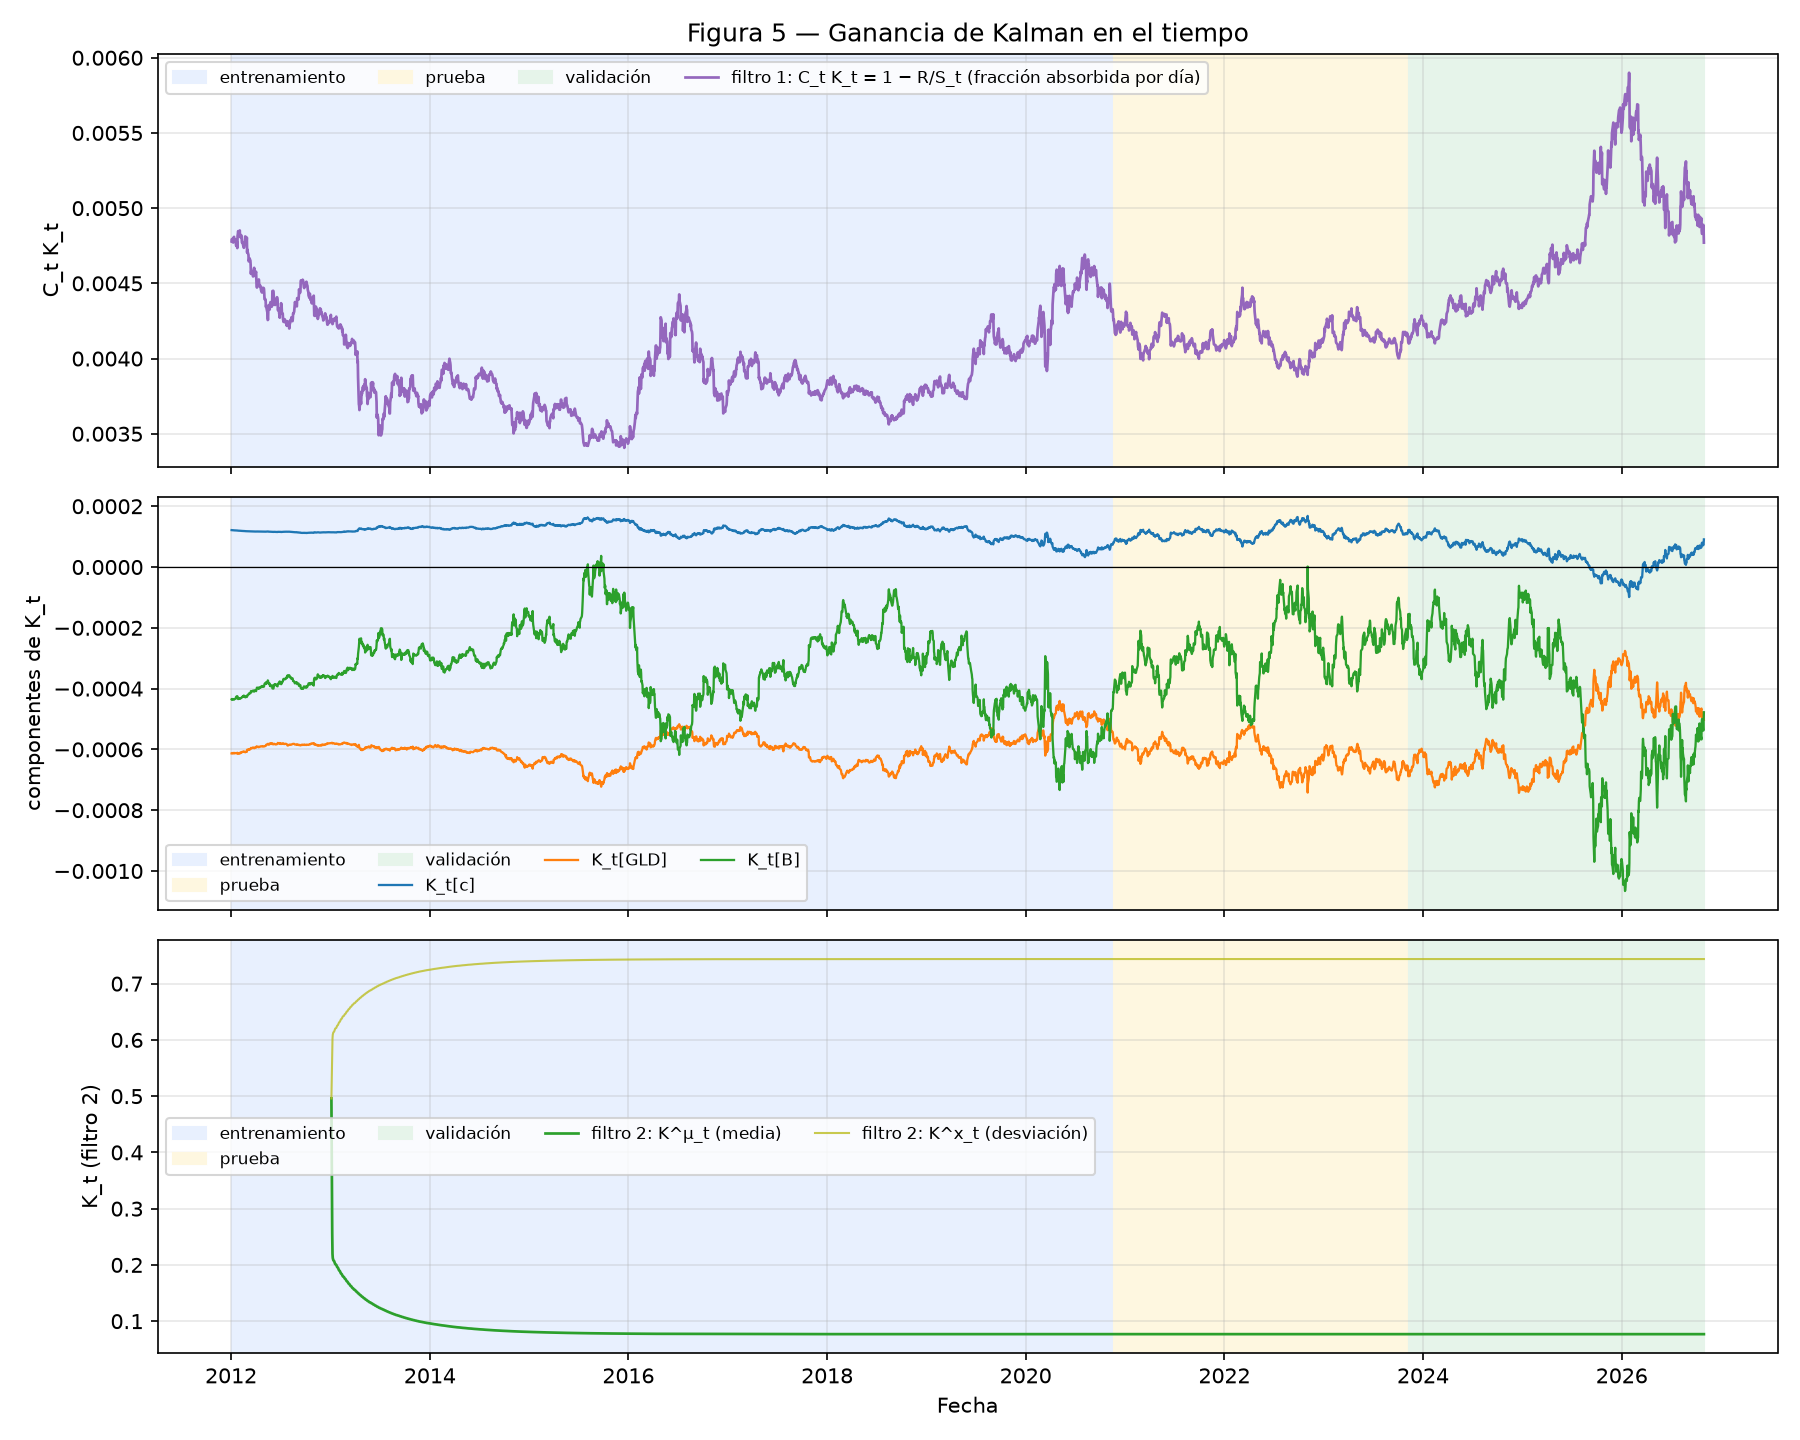

In [9]:
display(Image(filename=str(FIGURES / "fig05_ganancia_kalman.png")))

## 10. El z-score en el tiempo

Vista previa: la **figura 6** con los umbrales de entrada, salida y stop se genera en la parte 05, cuando el grid
search en train los fije.

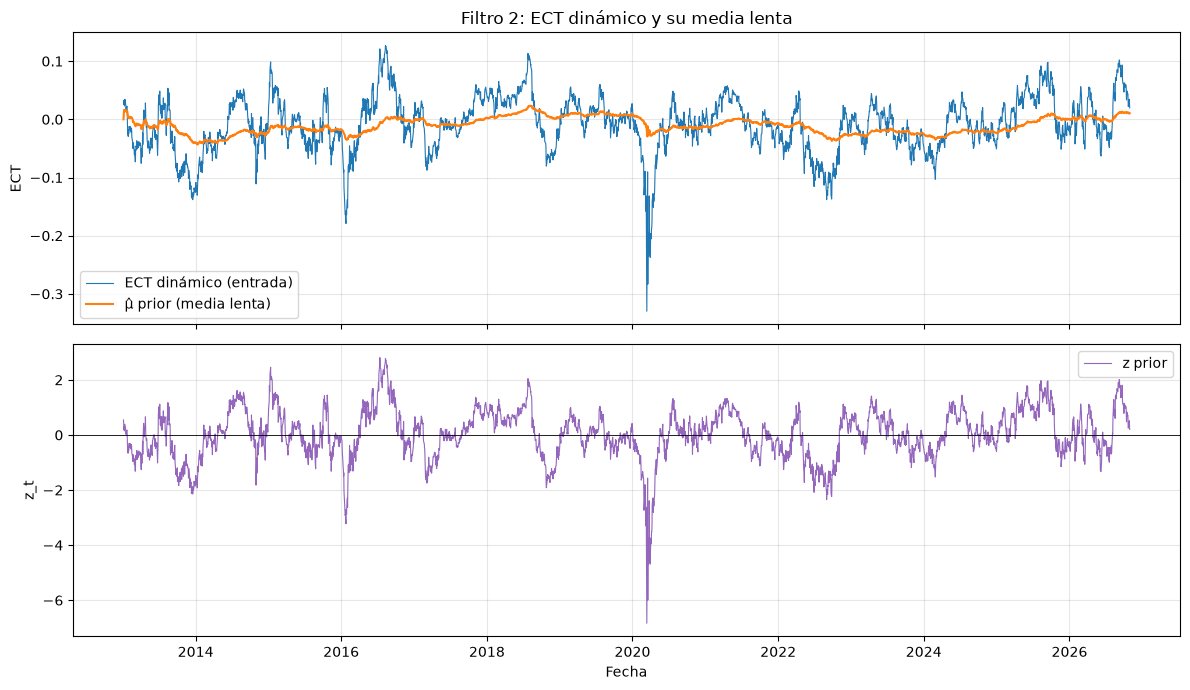

,mean,std,frac |z| > 2
split,,,
train,-0.0030,0.9921,0.0468
test,-0.0719,0.7765,0.0107
validation,0.2885,0.7442,0.0013


In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(kf2.index, kf2["ect"], linewidth=0.8, label="ECT dinámico (entrada)")
axes[0].plot(kf2.index, kf2["mu_prior"], linewidth=1.5, label="μ̂ prior (media lenta)")
axes[0].set_ylabel("ECT"); axes[0].set_title("Filtro 2: ECT dinámico y su media lenta"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(kf2.index, kf2["zscore"], linewidth=0.8, color="tab:purple", label="z prior")
axes[1].axhline(0, color="black", linewidth=0.6)
axes[1].set_ylabel("z_t"); axes[1].set_xlabel("Fecha"); axes[1].legend(); axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()
operable.groupby("split", sort=False)["zscore"].agg(["mean", "std", lambda z: (z.abs() > 2).mean()]).rename(
    columns={"<lambda_0>": "frac |z| > 2"})

## 11. Formulación Powell del filtro 2

Texto completo en `docs/powell.md` (sección filtro 2).

| Elemento | Filtro 2 | En el código |
|---|---|---|
| Estado S_t | Información I_t = ECT_t; creencia B_t = (μ̂_{t\|t}, x̂_{t\|t}, P_{t\|t}) | `SignalFilter.state`, `P_cov` |
| Decisión x_t | La corrección de la creencia K_t ν_t | `update()` |
| Información exógena W_{t+1} | El ECT del día siguiente (sale del filtro 1) | `ect_dynamic` |
| Transición | Predecir con A = diag(1, φ) y Q; actualizar con ν, S, K | `predict()`, `update()` |
| Objetivo | min E[Σ ν_t²] (verosimilitud de q_x, r), con la media lenta frente a la reversión (q_μ) | `calibrate_signal_filter` |
| Política | PFA con θ = (φ, q_μ, q_x, r); la regla K_t se derivó analíticamente | — |

## 12. Qué recibe la parte 05

`artifacts/kf2_signal.parquet`: **`zscore`** (prior, la señal), `burn_in` (no operar) y `split`. El grid search de
umbrales, stop y holding máximo se hace solo con train. Con la tercia el z se mantiene acotado fuera de muestra
(desviación 0.78 / 0.74 en prueba / validación, media de validación +0.29 y |z| > 2 solo el 1 % y el 0.1 % de los días):
la deriva de la relación es lenta y la media del filtro la va siguiendo. En la iteración 1 (GLD-GDX-AEM-FNV), el z de
validación tenía media +0.44 y |z| > 2 la mitad de los días.

## Resumen de resultados (parte 04)

| Resultado | Valor |
|---|---|
| Entrada | ECT dinámico del filtro 1 (pesos prior) de la tercia GLD-GDX-B, desde 2013-01-04 |
| Modelo | Estado aumentado: media lenta μ_t + desviación AR(1) x_t; el nivel local de clase es el caso x ≡ 0 |
| Por qué | El ECT revierte en ≈ 22 días; el nivel local o persigue al spread (z sin señal, vida media 0.7 días, no paga costos) o deja innovaciones autocorrelacionadas (≈ 0.95, falla la prueba 4) |
| φ | 0.969 (vida media 22.1 días, OU en train) |
| q_x, r | 1.1 × 10⁻⁴ y 2.8 × 10⁻⁵ (máxima verosimilitud en train) |
| q_μ | 9.3 × 10⁻⁷ (separación de escalas: μ̂ absorbe 20 % de un desplazamiento en 2 vidas medias, mismo criterio que el filtro 1) |
| z-score | z_t = (ECT_t − μ̂_{t\|t−1}) / σ̂_{t\|t−1} con estadísticos **prior**; σ̂ ≈ 0.045 |
| Ganancias de estado estable | K^μ ≈ 0.08, K^x ≈ 0.74 |
| Prueba 4 (train) | varianza de ν/√S = 0.995 (tolerancia [0.9, 1.1]); Ljung–Box rezago 1 p = 0.62 |
| Verificación | reproduce el ejemplo 2 de la sesión 13; z_post = (1 − K) z_prior; z causal (truncar no lo cambia) |
| z en train / prueba / validación | desviación 0.99 / 0.78 / 0.74; media de validación +0.29 |

- **Limitación:** Ljung–Box a 5–10 rezagos rechaza con cualquier modelo (autocorrelaciones pequeñas que vienen del ECT);
  fuera de muestra la varianza de las innovaciones queda por debajo de 1 (el filtro sobreestima el ruido).
- **Para la parte 05:** el z queda acotado fuera de muestra; el stop y el holding máximo siguen siendo la defensa si la
  relación se rompe.